# Dataset Exploration — Optdigits (original 32×32 bitmaps)

**Project:** *When Memories Compete: How Similarity Affects Memory Retrieval in Hopfield Networks*

This notebook only **explores the dataset**. No Hopfield network is built here.

### File format (checked by inspecting `data/optdigits-orig.cv` directly)
- **Lines 1–21: header** with metadata, e.g. `entwidth = 32`, `entheight = 32`, `ntot = 946`, `whitepix = 0`.
- **Then 946 digit blocks.** Each block has 33 lines:
  - 32 lines of exactly 32 characters, each `0` or `1` (one row of the image);
  - 1 label line holding the digit with a leading space, e.g. `" 5"`.
- `whitepix = 0` means **0 = white background** and **1 = black ink**.
- Check: 21 + 946 × 33 = 31,239 lines, which matches the file length.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Jupyter runs the notebook from its own folder (notebooks/), but the data is in
# the project root (hopfield-memory/data/). Look in both places so the notebook
# works either way.
DATA_FILE = "optdigits-orig.cv"
candidates = [Path("data") / DATA_FILE, Path("..") / "data" / DATA_FILE]
path = next((p for p in candidates if p.exists()), None)
if path is None:
    raise FileNotFoundError(f"Could not find {DATA_FILE} in: {[str(p) for p in candidates]}")

print("Loading:", path.resolve())

Loading: /Users/blessingngwechelseandeh/Desktop/hopfield-memory/data/optdigits-orig.cv


## 1. Look at the raw file
Print the first lines so we can see the format with our own eyes before parsing.

In [2]:
lines = path.read_text().splitlines()   # list of strings, one per line
print("Total lines in file:", len(lines))
print()

# Show the header plus the whole first digit block (21 header + 33 block lines).
for i, line in enumerate(lines[:54]):
    print(f"{i+1:3d} | {line!r}")   # !r shows quotes, so leading spaces are visible

Total lines in file: 31239

  1 | 'BU handwritten digit database: E Alpaydin C Kaynak 1995'
  2 | 'Cross-validation file'
  3 | ''
  4 | 'entwidth = 32'
  5 | 'entheight = 32'
  6 | 'depth = 1'
  7 | 'density = 300'
  8 | 'whitepix = 0'
  9 | 'ntot = 946'
 10 | 'ndigit = 946'
 11 | 'nlower = 0'
 12 | 'nupper = 0'
 13 | 'nparag = 0'
 14 | 'firstdigit = 0'
 15 | 'lastdigit = 945'
 16 | 'firstlower = 945'
 17 | 'lastlower = 945'
 18 | 'firstupper = 945'
 19 | 'lastupper = 945'
 20 | 'firstparag = 945'
 21 | 'lastparag = 945'
 22 | '00000000000001100111100000000000'
 23 | '00000000000111111111111111000000'
 24 | '00000000011111111111111111110000'
 25 | '00000000011111111111111111110000'
 26 | '00000000011111111101000001100000'
 27 | '00000000011111110000000000000000'
 28 | '00000000111100000000000000000000'
 29 | '00000001111100000000000000000000'
 30 | '00000001111100011110000000000000'
 31 | '00000001111100011111000000000000'
 32 | '00000001111111111111111000000000'
 33 | '00000001111111

## 2. Parse the images and labels

Plan:
1. Skip the 21 header lines.
2. Read the rest in chunks of 33 lines: 32 pixel rows plus 1 label.
3. Turn each pixel row (a string like `"000110..."`) into a list of integers.

Every block is checked as we go, so a problem in the format raises an error instead of quietly producing bad data.

In [3]:
HEADER_LINES = 21    # metadata lines at the top of the file
IMG_SIZE = 32        # images are 32 x 32 pixels
BLOCK = IMG_SIZE + 1 # 32 pixel rows + 1 label line

body = lines[HEADER_LINES:]   # everything after the header

images = []
labels = []

for start in range(0, len(body), BLOCK):
    block = body[start:start + BLOCK]
    if len(block) < BLOCK:            # stop if there is a partial block at the end
        break

    pixel_rows = block[:IMG_SIZE]     # first 32 lines = image
    label_line = block[IMG_SIZE]      # 33rd line = label

    # Check that every pixel row has 32 characters, all '0' or '1'.
    for row in pixel_rows:
        if len(row) != IMG_SIZE or set(row) - {"0", "1"}:
            raise ValueError(f"Bad pixel row in block starting at body line {start}: {row!r}")

    # "0011..." -> [0, 0, 1, 1, ...]; stack 32 rows into a 32x32 array.
    image = np.array([[int(ch) for ch in row] for row in pixel_rows], dtype=np.int8)

    # .strip() removes the leading space in " 5", then int() converts it to 5.
    label = int(label_line.strip())

    images.append(image)
    labels.append(label)

# Convert the lists to NumPy arrays:
#   images -> shape (N, 32, 32)
#   labels -> shape (N,)
images = np.array(images)
labels = np.array(labels)

print("Parsed", len(images), "images")

Parsed 946 images


## 3. Check the dimensions, the image count, and that pixels are binary

In [4]:
print("images shape:", images.shape)   # expect (946, 32, 32)
print("labels shape:", labels.shape)   # expect (946,)
print("pixel dtype :", images.dtype)

unique_pixels = np.unique(images)
print("unique pixel values:", unique_pixels)   # expect [0 1]
print("unique labels      :", np.unique(labels))  # expect 0..9

# The header says ntot = 946, so compare our count with it.
assert images.shape == (946, 32, 32), "unexpected image array shape"
assert labels.shape == (946,), "unexpected label array shape"
assert set(unique_pixels) <= {0, 1}, "pixels are not binary"
assert set(np.unique(labels)) <= set(range(10)), "labels outside 0-9"

# Extra context: what share of pixels is ink (1)?
# Hopfield networks are sensitive to how sparse patterns are, so this is useful to know.
print(f"fraction of pixels that are 1 (ink): {images.mean():.3f}")
print("All checks passed.")

images shape: (946, 32, 32)
labels shape: (946,)
pixel dtype : int8
unique pixel values: [0 1]
unique labels      : [0 1 2 3 4 5 6 7 8 9]
fraction of pixels that are 1 (ink): 0.305
All checks passed.


## 4. Show 10 sample digits
One example of each digit 0–9: the first time each label appears in the file.

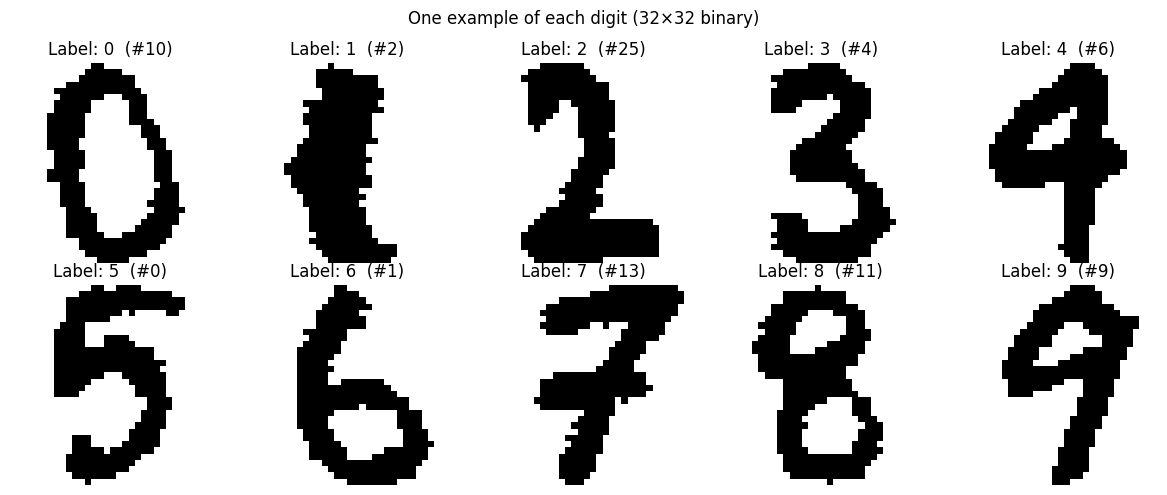

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for digit, ax in zip(range(10), axes.flat):
    idx = np.where(labels == digit)[0][0]   # index of the first image with this label
    # cmap="gray_r" (reversed gray): 0 -> white, 1 -> black, so it looks like ink on paper.
    ax.imshow(images[idx], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"Label: {labels[idx]}  (#{idx})")
    ax.axis("off")

fig.suptitle("One example of each digit (32×32 binary)")
plt.tight_layout()
plt.show()

## 5. Number of examples per digit

digit 0: 87
digit 1: 97
digit 2: 92
digit 3: 85
digit 4: 114
digit 5: 108
digit 6: 87
digit 7: 96
digit 8: 91
digit 9: 89
total  : 946


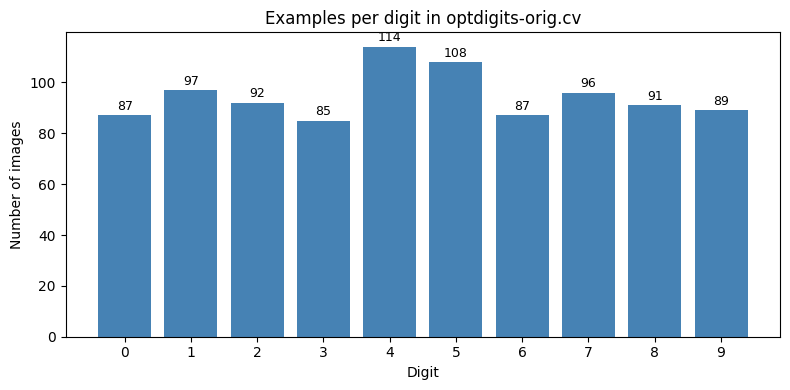

In [6]:
# np.bincount counts how many times each integer 0..9 appears in labels.
counts = np.bincount(labels, minlength=10)

for digit, n in enumerate(counts):
    print(f"digit {digit}: {n}")
print("total  :", counts.sum())

plt.figure(figsize=(8, 4))
plt.bar(range(10), counts, color="steelblue")
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Number of images")
plt.title("Examples per digit in optdigits-orig.cv")
for d, n in enumerate(counts):
    plt.text(d, n + 1, str(n), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()